# DAT301m — BẢN TỔNG HỢP CUỐI, TIÊU CHÍ ACCURACY
**Nhóm:** Team 1 (Tuấn, Chiến, Trà, Huy, Duy).

## Tiêu chí
Bảng xếp hạng hiệu năng của [cuộc thi gốc](https://https-deeplearning-ai.github.io/data-centric-comp/) dùng **Accuracy**; cuộc thi còn có hạng mục Most Innovative riêng.

Notebook dùng **accuracy** để báo cáo, chọn checkpoint và chọn stage. Accuracy = số dự đoán argmax đúng / tổng ảnh. Mỗi stage giữ checkpoint có `val_accuracy` cao nhất trong 15 epoch; nếu hòa giữ epoch đạt đỉnh đầu tiên. Chọn stage theo validation accuracy, nếu hòa giữ stage có chỉ số nhỏ hơn. Label Book chỉ để báo cáo. Categorical cross-entropy là loss huấn luyện, không phải tiêu chí lựa chọn.

## Kết quả lần chạy hiện tại
Bảng dưới đối chiếu trực tiếp với output đã lưu trong **submission.ipynb**, sử dụng checkpoint theo accuracy. Đây là kết quả chạy lại, thay thế bảng lịch sử chọn theo F1 trước đó. Cả sáu checkpoint đã được đánh giá trên validation và Label Book.

| Stage | Số ảnh train | Epoch được chọn | Validation accuracy | Label Book accuracy |
|---|---:|---:|---:|---:|
| 0 | 2,067 | 15 | 607/813 (74.66%) | 31/52 (59.62%) |
| 1 | 1,898 | 15 | 582/813 (71.59%) | 33/52 (63.46%) |
| 2 | 3,796 | 10 | 681/813 (83.76%) | 35/52 (67.31%) |
| 3 | 7,500 | 10 | 718/813 (88.31%) | 43/52 (82.69%) |
| 4 | 9,500 | 14 | 729/813 (89.67%) | 41/52 (78.85%) |
| 5 | 9,900 | 15 | 723/813 (88.93%) | 42/52 (80.77%) |

**Mô hình được chọn: Stage 4, epoch 14**, validation **729/813 = 89,67%**, Label Book **41/52 = 78,85%**. Đây là lựa chọn theo validation, không theo Label Book.

Trong sáu checkpoint được báo cáo, **Stage 3, epoch 10** có Label Book cao nhất: **43/52 = 82,69%**. Không dùng điểm này để chọn lại mô hình. Chưa stage nào đạt mục tiêu Label Book 90%; với 52 ảnh cần ít nhất 47 ảnh đúng (90,38%).

## Dữ liệu và phạm vi
Stage 0 dùng 2.067 ảnh train gốc. Stage 1 giữ nguyên 1.898 ảnh đã clean và sửa nhãn thủ công. Stage 2 bổ sung view căn giữa thành 3.796 ảnh; Stage 3/4/5 có 7.500/9.500/9.900 ảnh. Không clean lại và không dùng thư mục removal. Validation 813 ảnh và Label Book 52 ảnh giữ nguyên. Audit ghi nhận 49 ảnh train trùng validation ở cả nguồn gốc và nguồn thủ công, không có ảnh train trùng Label Book; chỉ báo cáo, không tự lọc.

Đây là **bản đồ án VGG16**. [README/script gốc](https://github.com/nov05/deeplearningai-data-centric-competition) dùng cut-off ResNet50 và giới hạn tổng train + validation dưới 10.000 ảnh. Stage 4/5 vượt giới hạn đó khi cộng 813 ảnh validation; các stage này được giữ làm thí nghiệm đồ án, không tuyên bố là bản nộp hợp lệ cho cuộc thi gốc.

## Cách dùng
Có thể xem kết quả và biểu đồ đã lưu mà không cần chạy lại. Để tái lập trên Colab: chọn GPU và upload `manual_train_curated.tar.gz` khi được hỏi; train gốc, validation và Label Book được khôi phục từ archive của repository. File ipynb không chứa weights. Log fit vẫn hiển thị loss để theo dõi tối ưu; bảng tổng hợp chỉ báo cáo accuracy và số đúng/tổng.

In [1]:
import sys
import os
import json
import hashlib
import shutil
import subprocess
import tarfile
import glob
from pathlib import Path, PurePosixPath

try:
    import google.colab
    IN_COLAB = True
    print("Đang chạy trên Google Colab")
except ImportError:
    IN_COLAB = False
    print("Đang chạy local")

REPO_URL = "https://github.com/nov05/deeplearningai-data-centric-competition.git"
CURATED_ARCHIVE_SHA256 = 'fd250c43c0eebb6ea56f523b917379f43434bfe7693cf330a4b4432218548e0f'
CURATED_TRAIN_COUNTS = {'i': 241, 'ii': 152, 'iii': 151, 'iv': 273, 'v': 183, 'vi': 166, 'vii': 173, 'viii': 178, 'ix': 210, 'x': 171}
ORIGINAL_DATA_ARCHIVE_SHA256 = "4c526a362ea66d75c088929b6cabc6dca468e38239b43a74526d24cfda86c1bc"
ORIGINAL_LB_ARCHIVE_SHA256 = "4e608305e58099d31c99aa0ed141f60dc738e12a55a7906a44ff9397dea246d8"
launch_dir = Path.cwd()

def select_curated_train_archive():
    """Use the uploaded curated snapshot; never silently use the original train."""
    candidates = [launch_dir / "manual_train_curated.tar.gz",
                  Path("/content/manual_train_curated.tar.gz"),
                  launch_dir / "deeplearningai-data-centric-competition/manual_train_curated.tar.gz"]
    for candidate in candidates:
        if candidate.is_file() and hashlib.sha256(candidate.read_bytes()).hexdigest() == CURATED_ARCHIVE_SHA256:
            print("Đã tìm thấy gói train đã clean:", candidate)
            return candidate.resolve()
    if not IN_COLAB:
        return None  # Local execution uses the current data/train directory below.
    from google.colab import files
    print("Chọn file manual_train_curated.tar.gz đã tải từ máy bạn.")
    uploaded = files.upload()
    data = uploaded.get("manual_train_curated.tar.gz")
    if data is None:
        raise FileNotFoundError("Chưa chọn đúng manual_train_curated.tar.gz. Chạy lại cell và chọn gói train đi kèm notebook.")
    if hashlib.sha256(data).hexdigest() != CURATED_ARCHIVE_SHA256:
        raise ValueError("Gói train không khớp snapshot đã clean đi kèm notebook. Chọn lại đúng file.")
    package = launch_dir / "manual_train_curated.tar.gz"
    package.write_bytes(data)
    return package.resolve()


train_package = select_curated_train_archive()

# Baseline must come from the unmodified repository archives, not local data/train.
if IN_COLAB:
    REPO_ROOT = Path("/content/deeplearningai-data-centric-competition")
else:
    REPO_ROOT = (launch_dir if (launch_dir / "original/data.tar.gz").is_file()
                 else launch_dir / "deeplearningai-data-centric-competition")
if not REPO_ROOT.exists():
    if not IN_COLAB:
        raise FileNotFoundError(f"Thiếu repository tại {REPO_ROOT}")
    subprocess.run(["git", "clone", REPO_URL, str(REPO_ROOT)], check=True)
REPO_ROOT = REPO_ROOT.resolve()
if not (REPO_ROOT / "original/data.tar.gz").is_file():
    raise FileNotFoundError(f"Repository thiếu original/data.tar.gz: {REPO_ROOT}")
os.chdir(REPO_ROOT)


def restore_original_archive(archive, expected_sha, output_parent, root_name):
    """Restore byte-identical original files into an isolated generated directory."""
    archive = Path(archive)
    if hashlib.sha256(archive.read_bytes()).hexdigest() != expected_sha:
        raise ValueError(f"Archive gốc không khớp SHA-256: {archive}")
    dest = Path(output_parent).resolve() / expected_sha[:16]
    dest.mkdir(parents=True, exist_ok=True)
    expected = {}
    with tarfile.open(archive, "r:gz") as tar:
        for member in tar.getmembers():
            parts = PurePosixPath(member.name).parts
            if not parts:
                continue
            if ".." in parts or PurePosixPath(member.name).is_absolute() or "\\" in member.name:
                raise ValueError(f"Đường dẫn archive không hợp lệ: {member.name}")
            target = dest.joinpath(*parts).resolve()
            if not target.is_relative_to(dest):
                raise ValueError(f"Đường dẫn nằm ngoài snapshot: {member.name}")
            if member.isdir():
                target.mkdir(parents=True, exist_ok=True)
            elif member.isfile():
                data = tar.extractfile(member).read()
                target.parent.mkdir(parents=True, exist_ok=True)
                target.write_bytes(data)
                expected[target.relative_to(dest).as_posix()] = hashlib.sha256(data).hexdigest()
            else:
                raise ValueError(f"Không chấp nhận link/file đặc biệt: {member.name}")
    actual = {f.relative_to(dest).as_posix(): hashlib.sha256(f.read_bytes()).hexdigest()
              for f in dest.rglob("*") if f.is_file()}
    if actual != expected:
        raise ValueError("Snapshot gốc bị thừa, thiếu hoặc đổi nội dung.")
    root = dest / root_name
    if not root.is_dir():
        raise FileNotFoundError(f"Không có {root_name} trong archive gốc.")
    return root


ORIGINAL_DATA_ROOT = restore_original_archive(
    REPO_ROOT / "original/data.tar.gz", ORIGINAL_DATA_ARCHIVE_SHA256,
    REPO_ROOT / "original_snapshots", "data")
ORIGINAL_TRAIN_ROOT = ORIGINAL_DATA_ROOT / "train"
ORIGINAL_VAL_ROOT = ORIGINAL_DATA_ROOT / "val"
ORIGINAL_LABEL_BOOK_ROOT = restore_original_archive(
    REPO_ROOT / "original/label_book.tar.gz", ORIGINAL_LB_ARCHIVE_SHA256,
    REPO_ROOT / "original_snapshots", "label_book")

def unpack_curated_train(archive, expected_sha, output_parent):
    if hashlib.sha256(Path(archive).read_bytes()).hexdigest() != expected_sha:
        raise ValueError("SHA-256 gói train không hợp lệ.")
    dest = Path(output_parent).resolve() / expected_sha[:16]
    dest.mkdir(parents=True, exist_ok=True)
    with tarfile.open(archive, "r:gz") as tar:
        manifest = json.load(tar.extractfile("manifest.json"))
        for member in tar.getmembers():
            if member.name == "manifest.json":
                continue
            parts = member.name.split("/")
            if (not member.isfile() or len(parts) != 3 or parts[0] != "train"
                    or parts[1] not in manifest["classes"] or parts[2] in ("", ".", "..")
                    or "\\" in member.name):
                raise ValueError(f"Đường dẫn không hợp lệ trong gói train: {member.name}")
            target = dest.joinpath(*parts)
            target.parent.mkdir(parents=True, exist_ok=True)
            with tar.extractfile(member) as src, target.open("wb") as out:
                shutil.copyfileobj(src, out)
    train = dest / "train"
    actual = {f.relative_to(train).as_posix(): hashlib.sha256(f.read_bytes()).hexdigest()
              for f in train.rglob("*") if f.is_file()}
    if actual != manifest["files"]:
        raise ValueError("Snapshot train bị thiếu, thừa hoặc đổi nội dung.")
    print("Đã xác minh train thủ công:", sum(manifest["counts"].values()), "ảnh", manifest["counts"])
    return train


if IN_COLAB:
    CURATED_TRAIN_ROOT = unpack_curated_train(
        train_package, CURATED_ARCHIVE_SHA256, REPO_ROOT / "manual_train_snapshot")
else:
    CURATED_TRAIN_ROOT = REPO_ROOT / "data/train"
if not CURATED_TRAIN_ROOT.is_dir():
    raise FileNotFoundError("Thiếu train bạn đã clean thủ công.")
print("Stage 0 — train gốc nguyên bản:", ORIGINAL_TRAIN_ROOT)
print("Stage 1+ — train đã clean thủ công:", CURATED_TRAIN_ROOT)
print("Validation gốc cố định:", ORIGINAL_VAL_ROOT)
print("Label Book gốc cố định:", ORIGINAL_LABEL_BOOK_ROOT)

Đang chạy trên Google Colab
Chọn file manual_train_curated.tar.gz đã tải từ máy bạn.


Saving manual_train_curated.tar.gz to manual_train_curated.tar.gz
Đã xác minh train thủ công: 1898 ảnh {'i': 241, 'ii': 152, 'iii': 151, 'iv': 273, 'ix': 210, 'v': 183, 'vi': 166, 'vii': 173, 'viii': 178, 'x': 171}
Stage 0 — train gốc nguyên bản: /content/deeplearningai-data-centric-competition/original_snapshots/4c526a362ea66d75/data/train
Stage 1+ — train đã clean thủ công: /content/deeplearningai-data-centric-competition/manual_train_snapshot/fd250c43c0eebb6e/train
Validation gốc cố định: /content/deeplearningai-data-centric-competition/original_snapshots/4c526a362ea66d75/data/val
Label Book gốc cố định: /content/deeplearningai-data-centric-competition/original_snapshots/4e608305e58099d3/label_book


<a id="setup"></a>
## 1. MÔ HÌNH VÀ CƠ SỞ LỰA CHỌN
- Giữ kiến trúc VGG16 scratch13Conv/5pool/3Dense, channels64/128/256/512/512, kernel3×3, ReLU, pool2×2; Dense512/512/10, dropout0,5, He-normal theo protocol đồ án đã chạy. Không đổi sang mô hình khác trong sửa metric này.
- InputRGB32×32, Rescaling1/255;32qua5poolstride2→1, giữ cùng loader mọi tập.
- Giữ Adam1e-4, batch32,15epoch, seed123 để so các stage theo cùng protocol. Đây là cấu hình đối chứng, chưa chứng minh tối ưu. Cùng epoch nhưng số optimizer updates khác theo số ảnh.
- `metrics=["accuracy"]`, checkpoint `monitor="val_accuracy", mode="max"`, stage có validation accuracy cao nhất được chọn. Hòa checkpoint giữ epoch đầu; hòa stage giữ chỉ sốstage nhỏ hơn. Label Book chỉ để báo cáo.
- Ngưỡng215 trên train0/64/255 tương đương mọi cutoff(64,255]; tẩy nền đổi0pixel. Padding15% cho occupancy lý tưởng76,92%; các target750/950/990 và biên augmentation là cấu hình đã chạy, không gọi là tối ưu đã chứng minh.
- Không có các metric precision/recall/F1/top-2 hoặc các thử nghiệm mới trong luồng báo cáo này. Giữ loss cross-entropy để tối ưu weights; loss không phải tiêu chí chọn checkpoint.

In [2]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import hashlib
import shutil
from PIL import Image

IMAGE_SIZE = (32, 32)
BATCH_SIZE = 32  # Giữ chung mọi stage; thử 64 bằng một lượt chạy riêng nếu cần đo tốc độ.
# Với cùng số epoch, batch lớn hơn làm giảm số bước cập nhật. Không đổi batch giữa các stage.
NUM_CLASSES = 10
CLASS_NAMES = ["i", "ii", "iii", "iv", "v", "vi", "vii", "viii", "ix", "x"]
RANDOM_SEED = 123
EPOCHS = 15

print(f"TensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"🚀 Thiết bị tăng tốc: ĐÃ BẬT GPU ({gpus[0].name}) -> Tốc độ huấn luyện cực nhanh!")
else:
    print("⚠️ Thiết bị hiện tại: CPU (Khuyên dùng: Trên Colab vào Menu Runtime -> Change runtime type -> Chọn T4 GPU)")

def build_fixed_vgg16_model():
    """
    KIẾN TRÚC VGG16 TỰ XÂY DỰNG TỪ ĐẦU (FROM SCRATCH) THEO YÊU CẦU GIẢNG VIÊN:
    - KHÔNG dùng thư viện có sẵn tf.keras.applications.VGG16
    - KHÔNG dùng pretrained weights ImageNet
    - Tự code tay đúng 13 lớp Conv2D + 5 lớp MaxPooling2D + 3 lớp Dense = 16 Layers VGG16
    - Khởi tạo He-Normal, cố định bất biến qua mọi Stage
    """
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(RANDOM_SEED)

    inputs = tf.keras.Input(shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3), name="input_image")
    x = tf.keras.layers.Rescaling(1.0 / 255.0, name="rescaling")(inputs)

    # Block 1 (2 Conv + MaxPool)
    x = tf.keras.layers.Conv2D(64, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b1_c1")(x)
    x = tf.keras.layers.Conv2D(64, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b1_c2")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2), name="b1_pool")(x)

    # Block 2 (2 Conv + MaxPool)
    x = tf.keras.layers.Conv2D(128, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b2_c1")(x)
    x = tf.keras.layers.Conv2D(128, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b2_c2")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2), name="b2_pool")(x)

    # Block 3 (3 Conv + MaxPool)
    x = tf.keras.layers.Conv2D(256, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b3_c1")(x)
    x = tf.keras.layers.Conv2D(256, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b3_c2")(x)
    x = tf.keras.layers.Conv2D(256, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b3_c3")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2), name="b3_pool")(x)

    # Block 4 (3 Conv + MaxPool)
    x = tf.keras.layers.Conv2D(512, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b4_c1")(x)
    x = tf.keras.layers.Conv2D(512, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b4_c2")(x)
    x = tf.keras.layers.Conv2D(512, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b4_c3")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2), name="b4_pool")(x)

    # Block 5 (3 Conv + MaxPool)
    x = tf.keras.layers.Conv2D(512, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b5_c1")(x)
    x = tf.keras.layers.Conv2D(512, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b5_c2")(x)
    x = tf.keras.layers.Conv2D(512, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b5_c3")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2), name="b5_pool")(x)

    # Classifier Head (13 Conv + 3 Dense = 16 Layers VGG16)
    x = tf.keras.layers.Flatten(name="flatten")(x)
    x = tf.keras.layers.Dense(512, activation="relu", kernel_initializer="he_normal", name="fc1")(x)
    x = tf.keras.layers.Dropout(0.5, name="dropout1")(x)
    x = tf.keras.layers.Dense(512, activation="relu", kernel_initializer="he_normal", name="fc2")(x)
    x = tf.keras.layers.Dropout(0.5, name="dropout2")(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="Fixed_VGG16_Scratch")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

print("✅ Đã khởi tạo cấu trúc Fixed VGG16 Scratch thành công (15.245.130 tham số).")

TensorFlow Version: 2.21.0
🚀 Thiết bị tăng tốc: ĐÃ BẬT GPU (/physical_device:GPU:0) -> Tốc độ huấn luyện cực nhanh!
✅ Đã khởi tạo cấu trúc Fixed VGG16 Scratch thành công (15.245.130 tham số).


<a id="stage0"></a>
## 2. TÁCH NGUỒN TRAIN GỐC / TRAIN THỦ CÔNG VÀ ĐÓNG BĂNG TẬP ĐÁNH GIÁ
Baseline đọc trực tiếp train khôi phục từ `original/data.tar.gz` của repository. Stage 1 đọc đúng train đã sửa nhãn và loại ảnh thủ công; chỉ lấy 10 thư mục nhãn, bỏ qua removal. Không tự loại ảnh trắng, bản sao, xung đột nhãn hay ảnh trùng tập đánh giá ở bất kỳ nguồn train nào. Chụp hash của hai nguồn train và hai tập đánh giá để kiểm tra không bị sửa trong quá trình chạy. Validation và Label Book luôn lấy từ cùng snapshot nguyên bản cho mọi stage.

In [3]:
from pathlib import Path

FAIR_ROOT = Path("accuracy_results_v1").resolve()
FAIR_ROOT.mkdir(exist_ok=True)
VAL_ROOT = ORIGINAL_VAL_ROOT
LB_ROOT = ORIGINAL_LABEL_BOOK_ROOT

def file_manifest(root):
    return {str(f.relative_to(root)): hashlib.sha256(f.read_bytes()).hexdigest()
            for f in sorted(root.rglob("*")) if f.is_file()}

EVAL_SNAPSHOT = {str(root): file_manifest(root) for root in (VAL_ROOT, LB_ROOT)}
assert all(EVAL_SNAPSHOT.values()), "Thiếu dữ liệu đánh giá."
def assert_eval_unchanged():
    for root, expected in EVAL_SNAPSHOT.items():
        assert file_manifest(Path(root)) == expected, f"Tập đánh giá đã thay đổi: {root}"

def pixel_hash(path):
    with Image.open(path) as im:
        gray = im.convert("L")
        return hashlib.sha256(str(gray.size).encode() + gray.tobytes()).hexdigest()

# Source selection only: no quality filtering, deduplication or relabeling.
RAW_SOURCES = {c: sorted((ORIGINAL_TRAIN_ROOT / c).glob("*.png")) for c in CLASS_NAMES}
MANUAL_SOURCES = {c: sorted((CURATED_TRAIN_ROOT / c).glob("*.png")) for c in CLASS_NAMES}
assert all(RAW_SOURCES.values()), "Train gốc thiếu lớp."
assert all(MANUAL_SOURCES.values()), "Train thủ công thiếu lớp."
assert all(f.parent.name in CLASS_NAMES for files in MANUAL_SOURCES.values() for f in files)
SOURCE_SNAPSHOTS = {str(root): file_manifest(root)
                    for root in (ORIGINAL_TRAIN_ROOT, CURATED_TRAIN_ROOT)}

def assert_source_data_unchanged():
    for root, expected in SOURCE_SNAPSHOTS.items():
        assert file_manifest(Path(root)) == expected, f"Nguồn train đã thay đổi: {root}"

print("Stage 0 — số ảnh train gốc (không lọc):", sum(map(len, RAW_SOURCES.values())))
print("Stage 1 — số ảnh train đã clean thủ công (không lọc lại):", sum(map(len, MANUAL_SOURCES.values())))
print("Các stage sau dùng đúng nguồn train thủ công; không dùng removal.")


def fresh_train_dir(name):
    dest = (FAIR_ROOT / name).resolve()
    assert dest.parent == FAIR_ROOT and dest != FAIR_ROOT, "Đường dẫn đầu ra không an toàn."
    if dest.exists():
        shutil.rmtree(dest)
    for c in CLASS_NAMES:
        (dest / c).mkdir(parents=True, exist_ok=True)
    return dest

def load_images(directory, training=False):
    return tf.keras.utils.image_dataset_from_directory(
        str(directory), labels="inferred", label_mode="categorical",
        class_names=CLASS_NAMES, color_mode="rgb", image_size=IMAGE_SIZE,
        interpolation="bilinear", batch_size=BATCH_SIZE,
        shuffle=training, seed=RANDOM_SEED)

BASELINE_DIR = ORIGINAL_TRAIN_ROOT
train_ds_raw = load_images(BASELINE_DIR, training=True)
val_ds_raw = load_images(VAL_ROOT)
lb_ds_raw = load_images(LB_ROOT)
STAGE_RESULTS = {}
STAGE_MODELS = {}
STAGE_DETAILS = {}
STAGE_HISTORIES = {}
BEST_CHECKPOINT_DETAILS = {}
BEST_CHECKPOINT_EPOCHS = {}


def accuracy_scores(y_true, probabilities):
    y_true=np.asarray(y_true,dtype=np.int64)
    probabilities=np.asarray(probabilities)
    if y_true.ndim!=1 or len(y_true)==0 or probabilities.shape!=(len(y_true),NUM_CLASSES):
        raise ValueError("Nhãn/xác suất rỗng hoặc sai kích thước.")
    if not np.isfinite(probabilities).all():
        raise ValueError("Có xác suất NaN/Inf.")
    predicted=probabilities.argmax(axis=1)
    correct=int(np.count_nonzero(predicted==y_true))
    return dict(metrics=dict(accuracy=correct/len(y_true),n_correct=correct,n_samples=int(len(y_true))))


def evaluate_accuracy(model,dataset,title):
    truth,probabilities=[],[]
    for images,labels in dataset:
        truth.append(np.asarray(labels).argmax(axis=1))
        probabilities.append(np.asarray(model(images,training=False)))
    if not truth: raise ValueError(f"Tập đánh giá rỗng: {title}")
    detail=accuracy_scores(np.concatenate(truth),np.concatenate(probabilities))
    m=detail["metrics"]
    print(f"{title}: accuracy={m['accuracy']:.2%}; đúng {m['n_correct']}/{m['n_samples']}")
    return detail


def plot_stage_accuracy(history,index):
    fig,ax=plt.subplots(figsize=(9,4))
    epochs=range(1,len(history.history["accuracy"])+1)
    ax.plot(epochs,history.history["accuracy"],label="Train accuracy")
    ax.plot(epochs,history.history["val_accuracy"],label="Validation accuracy")
    ax.set_xlabel("Epoch");ax.set_ylabel("Accuracy");ax.set_ylim(0,1)
    ax.set_title(f"Stage {index}");ax.legend();ax.grid(alpha=0.3)
    fig.tight_layout();fig.savefig(FAIR_ROOT/f"stage{index}_accuracy.png",dpi=130)
    plt.show()


def run_stage(index,directory):
    assert_source_data_unchanged(); assert_eval_unchanged()
    tf.keras.utils.set_random_seed(RANDOM_SEED)
    train=load_images(directory,training=True)
    model=build_fixed_vgg16_model()
    checkpoint=FAIR_ROOT/f"stage{index}_best_val_accuracy.weights.h5"
    checkpoint.unlink(missing_ok=True)
    history=model.fit(train,validation_data=val_ds_raw,epochs=EPOCHS,verbose=1,
        callbacks=[tf.keras.callbacks.CSVLogger(str(FAIR_ROOT/f"stage{index}_training.csv")),
                   tf.keras.callbacks.ModelCheckpoint(str(checkpoint),monitor="val_accuracy",mode="max",
                                                      save_best_only=True,save_weights_only=True,verbose=1)])
    final_validation=evaluate_accuracy(model,val_ds_raw,f"Stage {index} — epoch cuối — Validation")
    final_book=evaluate_accuracy(model,lb_ds_raw,f"Stage {index} — epoch cuối — Label Book")
    STAGE_DETAILS[index]=dict(validation=final_validation,label_book=final_book)
    STAGE_RESULTS[index]=dict(val_accuracy=final_validation["metrics"]["accuracy"],
                             label_book_accuracy=final_book["metrics"]["accuracy"])
    STAGE_MODELS[index]=model;STAGE_HISTORIES[index]=history
    final_weights=FAIR_ROOT/f"stage{index}_final.weights.h5"
    model.save_weights(str(final_weights))
    artifact=dict(stage=index,epochs=EPOCHS,batch_size=BATCH_SIZE,seed=RANDOM_SEED,
                  train_images=len(train.file_paths),train_directory=str(Path(directory).resolve()),
                  source_archive_sha256=ORIGINAL_DATA_ARCHIVE_SHA256 if index==0 else CURATED_ARCHIVE_SHA256,
                  actual_optimizer_updates=int(model.optimizer.iterations.numpy()),
                  optimizer_config=model.optimizer.get_config(),model_config=model.get_config(),
                  tensorflow_version=tf.__version__,selection_metric="val_accuracy",tie_rule="earliest_epoch",
                  history={k:[float(v) for v in values] for k,values in history.history.items()},
                  final_epoch=STAGE_DETAILS[index])
    if not checkpoint.is_file():raise RuntimeError("Không có checkpoint accuracy hợp lệ.")
    selected_epoch=int(np.argmax(history.history["val_accuracy"]))+1
    try:
        model.load_weights(str(checkpoint))
        validation=evaluate_accuracy(model,val_ds_raw,f"Stage {index} — best accuracy epoch {selected_epoch} — Validation")
        book=evaluate_accuracy(model,lb_ds_raw,f"Stage {index} — best accuracy epoch {selected_epoch} — Label Book")
        BEST_CHECKPOINT_DETAILS[index]=dict(validation=validation,label_book=book)
        BEST_CHECKPOINT_EPOCHS[index]=selected_epoch
        artifact.update(selected_epoch=selected_epoch,checkpoint=str(checkpoint),best_accuracy=BEST_CHECKPOINT_DETAILS[index])
    finally:
        model.load_weights(str(final_weights))
    (FAIR_ROOT/f"stage{index}_accuracy_metrics.json").write_text(json.dumps(artifact,ensure_ascii=False,indent=2),encoding="utf-8")
    plot_stage_accuracy(history,index)
    assert_source_data_unchanged();assert_eval_unchanged()
    return model,history

Stage 0 — số ảnh train gốc (không lọc): 2067
Stage 1 — số ảnh train đã clean thủ công (không lọc lại): 1898
Các stage sau dùng đúng nguồn train thủ công; không dùng removal.
Found 2067 files belonging to 10 classes.
Found 813 files belonging to 10 classes.
Found 52 files belonging to 10 classes.


## 3. BASELINE — TRAIN GỐC CHƯA LÀM SẠCH
Dùng đủ ảnh và nhãn từ train gốc trong repository, kể cả ảnh trắng/sai nhãn/bản sao nếu có. Không offline preprocessing, không khử trùng, không augmentation. Chỉ dùng bước RGB/resize 32 × 32 bắt buộc của loader và Rescaling(1/255) trong mô hình như mọi stage.

**Kết quả hiện tại:** checkpoint epoch 15, validation **607/813 = 74,66%**, Label Book **31/52 = 59,62%**. Đây là mốc đối chứng cho các stage sau.

Found 2067 files belonging to 10 classes.
Epoch 1/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step - accuracy: 0.1124 - loss: 2.3778
Epoch 1: val_accuracy improved from None to 0.10209, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage0_best_val_accuracy.weights.h5

Epoch 1: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage0_best_val_accuracy.weights.h5
65/65 ━━━━━━━━━━━━━━━━━━━━ 54s 490ms/step - accuracy: 0.1132 - loss: 2.3254 - val_accuracy: 0.1021 - val_loss: 2.3026
Epoch 2/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.1245 - loss: 2.2965
Epoch 2: val_accuracy improved from 0.10209 to 0.10332, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage0_best_val_accuracy.weights.h5

Epoch 2: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage0_best_val_accuracy.weights.h5
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/ste

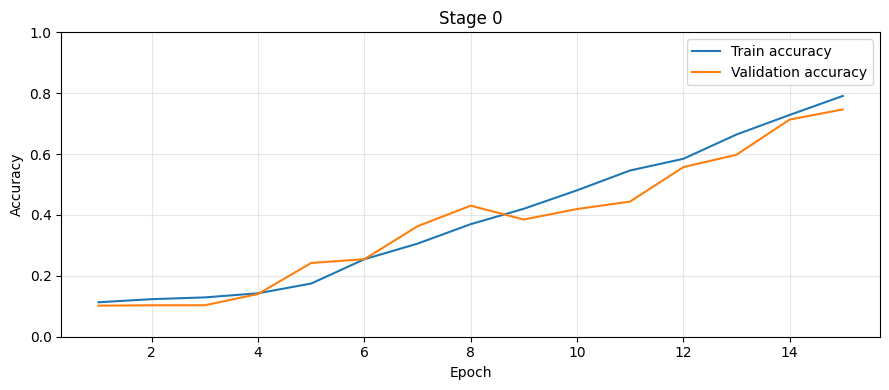

In [4]:
baseline_model, history_s0 = run_stage(0, BASELINE_DIR)

## 4. BÁO CÁO TRÙNG TẬP ĐÁNH GIÁ — CHỈ ĐỌC
Đếm các ảnh train có cùng pixel grayscale/kích thước với validation hoặc Label Book. Đây là audit, không phải bước clean: không xóa, sửa, di chuyển hay lọc ảnh. Nếu nguồn gốc có trùng train/validation thì điểm validation chưa phải ước lượng độc lập hoàn toàn; giữ nguyên và báo cáo rõ theo yêu cầu baseline nguyên bản.

In [5]:
val_hashes = {pixel_hash(f) for c in CLASS_NAMES for f in sorted((VAL_ROOT / c).glob("*.png"))}
lb_hashes = {pixel_hash(f) for c in CLASS_NAMES for f in sorted((LB_ROOT / c).glob("*.png"))}
SOURCE_AUDIT = {}
for name, sources in [("original", RAW_SOURCES), ("manual", MANUAL_SOURCES)]:
    hashes = [pixel_hash(f) for files in sources.values() for f in files]
    SOURCE_AUDIT[name] = dict(
        train_images=len(hashes),
        overlaps_validation=sum(h in val_hashes for h in hashes),
        overlaps_label_book=sum(h in lb_hashes for h in hashes))
    print(name, SOURCE_AUDIT[name])
print("Chỉ báo cáo trùng; không tự lọc lại train gốc hoặc train thủ công.")
assert_source_data_unchanged()
assert_eval_unchanged()

# TRAIN-ONLY DIAGNOSTICS: evidence for design decisions, never a cleaning step.
def summarize_training_data(root, class_names, target_side=32, thresholds=(200, 215, 230),
                            batch_size=32, epochs=15, n_original=2067, stage_targets=(750, 950, 990)):
    root = Path(root)
    counts = {c: 0 for c in class_names}
    widths, heights = [], []
    pixel_hist = np.zeros(256, dtype=np.int64)
    border_hist = np.zeros(256, dtype=np.int64)
    geometry = {str(t): dict(empty=0, center_offset_32px=[], bbox_max_fraction=[], touches_border=0)
                for t in thresholds}
    source = hashlib.sha256()
    for c in class_names:
        for f in sorted((root / c).glob('*.png')):
            counts[c] += 1
            source.update(f.relative_to(root).as_posix().encode('utf8'))
            source.update(hashlib.sha256(f.read_bytes()).digest())
            with Image.open(f) as im:
                arr = np.asarray(im.convert('L'))
            h, w = arr.shape
            widths.append(w); heights.append(h)
            pixel_hist += np.bincount(arr.ravel(), minlength=256)
            border = np.zeros(arr.shape, dtype=bool)
            border[0,:] = border[-1,:] = True
            border[:,0] = border[:,-1] = True
            border_hist += np.bincount(arr[border], minlength=256)
            for t in thresholds:
                g = geometry[str(t)]
                mask = arr < t
                ys, xs = np.where(mask)
                if len(xs) == 0:
                    g['empty'] += 1
                    continue
                cx = (xs.min()+xs.max())/2
                cy = (ys.min()+ys.max())/2
                dx = abs(cx-(w-1)/2)/w
                dy = abs(cy-(h-1)/2)/h
                g['center_offset_32px'].append(float(max(dx,dy)*target_side))
                g['bbox_max_fraction'].append(float(max((xs.max()-xs.min()+1)/w,
                                                        (ys.max()-ys.min()+1)/h)))
                g['touches_border'] += int(mask[border].any())
    total = sum(counts.values())
    if not total or not all(counts.values()):
        raise ValueError('Train phải có ít nhất một ảnh trong mỗi lớp hợp lệ.')
    def quantiles(values):
        if not values:
            return None
        return {f'p{p}': float(np.percentile(values,p)) for p in (0,5,25,50,75,95,100)}
    for g in geometry.values():
        for key in ('center_offset_32px','bbox_max_fraction'):
            g[key] = quantiles(g[key])
        g['touches_border_fraction'] = g['touches_border']/total
    majority = max(counts.values())
    # Minimum equal target that retains all existing raw+centered views.
    m = 2*majority
    steps = {str(k): int(np.ceil(v/batch_size))*epochs for k,v in {
        '0_original':n_original,'1_manual':total,'2_raw_centered':2*total,
        '3_current_target':len(class_names)*stage_targets[0],
        '4_current_target':len(class_names)*stage_targets[1],
        '5_current_target':len(class_names)*stage_targets[2]}.items()}
    return dict(
        n_images=total,class_counts=counts,source_manifest_sha256=source.hexdigest(),
        imbalance_ratio=majority/min(counts.values()),width_px=quantiles(widths),height_px=quantiles(heights),
        geometry_by_threshold=geometry,pixel_histogram=pixel_hist.tolist(),
        perimeter_histogram=border_hist.tolist(),
        fraction_all_pixels_above_215=float(pixel_hist[216:].sum()/pixel_hist.sum()),
        fraction_perimeter_pixels_above_215=float(border_hist[216:].sum()/border_hist.sum()),
        minimum_balanced_target_manual=majority,minimum_balanced_target_raw_centered=m,
        minimum_balanced_total_raw_centered=m*len(class_names),
        observed_gray_values=np.flatnonzero(pixel_hist).astype(int).tolist(),
        pixels_changed_by_whitening_above_215=int(pixel_hist[216:255].sum()),
        pixels_changed_by_dark_boost_07=int(pixel_hist[1:120].sum()),
        planned_optimizer_steps=steps, batch_size=batch_size, epochs=epochs,
        measurement_notes=[
            'Train only; removal is excluded by explicit class list. No input images are modified or removed.',
            'Bounding boxes use a threshold proxy, not ground-truth foreground segmentation.',
            'Border pixels can contain ink; border brightness does not prove a background threshold is safe.',
            'Diagnostic thresholds 200/215/230 are sensitivity probes, not selected optimum thresholds.',
            'Optimizer step counts use the declared batch/epoch budget and keep the last partial batch; they do not prove convergence.'
        ])


TRAIN_DIAGNOSTICS = summarize_training_data(
    CURATED_TRAIN_ROOT, CLASS_NAMES, target_side=IMAGE_SIZE[0],
    batch_size=BATCH_SIZE, epochs=EPOCHS,
    n_original=sum(map(len, RAW_SOURCES.values())), stage_targets=(750, 950, 990))
(FAIR_ROOT / "training_decision_diagnostics.json").write_text(
    json.dumps(TRAIN_DIAGNOSTICS, ensure_ascii=False, indent=2), encoding="utf-8")
print("Số ảnh theo lớp — cơ sở kiểm tra cân bằng:")
display(pd.DataFrame.from_dict(TRAIN_DIAGNOSTICS["class_counts"], orient="index", columns=["n_train"]))
print("Mức xám nguồn:", TRAIN_DIAGNOSTICS["observed_gray_values"])
print("Pixel đổi bởi tẩy nền215:", TRAIN_DIAGNOSTICS["pixels_changed_by_whitening_above_215"])
print("Target cân bằng nhỏ nhất giữ raw+center:", TRAIN_DIAGNOSTICS["minimum_balanced_target_raw_centered"])
print("Độ lệch tâm bbox quy đổi32px:", TRAIN_DIAGNOSTICS["geometry_by_threshold"]["215"]["center_offset_32px"])
print("Số optimizer updates dự kiến:", TRAIN_DIAGNOSTICS["planned_optimizer_steps"])
print("Đây là đo dữ liệu; các con số750/950/990 và biên augmentation chưa được chứng minh tối ưu.")
assert_source_data_unchanged()
assert_eval_unchanged()

# Exact overlap pairs: list only; do not remove or relabel source images.
def image_fingerprints(path):
    path=Path(path)
    with Image.open(path) as im:
        gray=im.convert('L')
        pixel_sha=hashlib.sha256(str(gray.size).encode()+gray.tobytes()).hexdigest()
    return pixel_sha, hashlib.sha256(path.read_bytes()).hexdigest()


def find_overlap_pairs(train_sources, heldout_roots, class_names):
    index={}
    for split,root in heldout_roots.items():
        for label in class_names:
            for f in sorted((Path(root)/label).glob('*.png')):
                pixel_sha,file_sha=image_fingerprints(f)
                index.setdefault(pixel_sha,[]).append((split,label,f,file_sha))
    rows=[]
    for source,sources in train_sources.items():
        for label,files in sources.items():
            for f in files:
                pixel_sha,file_sha=image_fingerprints(f)
                for split,held_label,held_path,held_file_sha in index.get(pixel_sha,[]):
                    rows.append(dict(train_source=source,train_label=label,train_path=str(Path(f).resolve()),
                                     heldout_split=split,heldout_label=held_label,
                                     heldout_path=str(held_path.resolve()),same_label=label==held_label,
                                     byte_identical=file_sha==held_file_sha,
                                     pixel_sha256=pixel_sha))
    return rows


OVERLAP_PAIRS = find_overlap_pairs(
    {"original": RAW_SOURCES, "manual": MANUAL_SOURCES},
    {"validation": VAL_ROOT, "label_book": LB_ROOT}, CLASS_NAMES)
overlap_columns = ["train_source", "train_label", "train_path", "heldout_split", "heldout_label",
                   "heldout_path", "same_label", "byte_identical", "pixel_sha256"]
overlap_table = pd.DataFrame(OVERLAP_PAIRS, columns=overlap_columns)
overlap_table.to_csv(FAIR_ROOT / "overlap_pairs.csv", index=False, encoding="utf-8-sig")
(FAIR_ROOT / "overlap_pairs.json").write_text(
    json.dumps(OVERLAP_PAIRS, ensure_ascii=False, indent=2), encoding="utf-8")
print("Các cặp overlap chính xác (đường dẫn và nhãn); toàn bộ lưu ở overlap_pairs.csv:")
display(overlap_table)
assert_source_data_unchanged()
assert_eval_unchanged()

original {'train_images': 2067, 'overlaps_validation': 49, 'overlaps_label_book': 0}
manual {'train_images': 1898, 'overlaps_validation': 49, 'overlaps_label_book': 0}
Chỉ báo cáo trùng; không tự lọc lại train gốc hoặc train thủ công.
Số ảnh theo lớp — cơ sở kiểm tra cân bằng:


,n_train
i,241
ii,152
iii,151
iv,273
v,183
vi,166
vii,173
viii,178
ix,210
x,171


Mức xám nguồn: [0, 64, 255]
Pixel đổi bởi tẩy nền215: 0
Target cân bằng nhỏ nhất giữ raw+center: 546
Độ lệch tâm bbox quy đổi32px: {'p0': 0.0, 'p5': 0.45818498557352066, 'p25': 1.6747665719422375, 'p50': 2.8468731212504954, 'p75': 4.282300787957764, 'p95': 6.77956510348441, 'p100': 12.846153846153847}
Số optimizer updates dự kiến: {'0_original': 975, '1_manual': 900, '2_raw_centered': 1785, '3_current_target': 3525, '4_current_target': 4455, '5_current_target': 4650}
Đây là đo dữ liệu; các con số750/950/990 và biên augmentation chưa được chứng minh tối ưu.
Các cặp overlap chính xác (đường dẫn và nhãn); toàn bộ lưu ở overlap_pairs.csv:


,train_source,train_label,train_path,heldout_split,heldout_label,heldout_path,same_label,byte_identical,pixel_sha256
0,original,i,/content/deeplearningai-data-centric-competiti...,validation,i,/content/deeplearningai-data-centric-competiti...,True,True,42b814e0e2145bb0dda20b8e446c1e12649001bd50c58f...
1,original,i,/content/deeplearningai-data-centric-competiti...,validation,i,/content/deeplearningai-data-centric-competiti...,True,True,d05c6198ebed366f876879abc92ccceb17060cdfe64dcc...
2,original,i,/content/deeplearningai-data-centric-competiti...,validation,i,/content/deeplearningai-data-centric-competiti...,True,True,36d4ebd202d12069f36fd1869b3fc54059e02ce3914f69...
3,original,i,/content/deeplearningai-data-centric-competiti...,validation,i,/content/deeplearningai-data-centric-competiti...,True,True,eed2333d1fa20be55798e98aca4f44c6040f33d4641dcf...
4,original,i,/content/deeplearningai-data-centric-competiti...,validation,i,/content/deeplearningai-data-centric-competiti...,True,True,07a462fec63052f2095cb3d5d1ef1b55679d8420664782...
...,...,...,...,...,...,...,...,...,...
93,manual,x,/content/deeplearningai-data-centric-competiti...,validation,x,/content/deeplearningai-data-centric-competiti...,True,True,8bf2b478c7264e34a3f2845644b71652760d834f961cfd...
94,manual,x,/content/deeplearningai-data-centric-competiti...,validation,x,/content/deeplearningai-data-centric-competiti...,True,True,c7cb773f8d6204aa6aeab720ee453fe9de9cbe74f92e1f...
95,manual,x,/content/deeplearningai-data-centric-competiti...,validation,x,/content/deeplearningai-data-centric-competiti...,True,True,186f148c9761499564e61f34ed3fe86ba428af8954abf9...
96,manual,x,/content/deeplearningai-data-centric-competiti...,validation,x,/content/deeplearningai-data-centric-competiti...,True,True,0107a01f31d00c7c12a485f9613ab6bb0bfd473085bb50...


<a id="stage1"></a>
# STAGE 1: TRAIN ĐÃ CLEAN VÀ SỬA NHÃN THỦ CÔNG
Dùng nguyên vẹn các ảnh trong 10 lớp của gói train bạn đã clean: ảnh kém chất lượng đã đưa vào removal, ảnh sai nhãn đã chuyển sang thư mục đúng. Không chạy cleaner, blacklist, loại ảnh trắng, khử trùng hay loại nhóm mâu thuẫn nhãn thêm lần nữa. Stage 1 giữ nguyên bytes/nhãn và không thêm ảnh. Chỉ thay nguồn train so với baseline; mô hình, loader, batch size, seed, optimizer, epoch và hai tập đánh giá giữ giống nhau.

## 1. CHỌN TRAIN THỦ CÔNG — KHÔNG CLEAN LẠI

In [6]:
MANUAL_TRAIN_DIR = CURATED_TRAIN_ROOT
assert all((MANUAL_TRAIN_DIR / c).is_dir() for c in CLASS_NAMES)
print("Stage 1 sử dụng nguyên vẹn train thủ công:", MANUAL_TRAIN_DIR)
print("Số ảnh:", sum(len(list((MANUAL_TRAIN_DIR / c).glob("*.png"))) for c in CLASS_NAMES))
assert_source_data_unchanged()
assert_eval_unchanged()

Stage 1 sử dụng nguyên vẹn train thủ công: /content/deeplearningai-data-centric-competition/manual_train_snapshot/fd250c43c0eebb6e/train
Số ảnh: 1898


## 2. HUẤN LUYỆN TRÊN TRAIN THỦ CÔNG
Không thay đổi ảnh hoặc nhãn đã clean. Validation và Label Book gốc cố định.

Checkpoint epoch 15 đạt validation **582/813 = 71,59%**, Label Book **33/52 = 63,46%**. So với baseline, validation giảm **3,08 điểm phần trăm** (25 ảnh đúng), còn Label Book tăng **3,85 điểm phần trăm** (2 ảnh đúng). Vì vậy lần chạy này chưa chứng minh clean thủ công cải thiện đồng thời cả hai tập. Chỉ có một lần chạy cho mỗi stage; chưa đủ để kết luận mức giảm/tăng ổn định. Số ảnh train giảm cũng làm số bước cập nhật trong 15 epoch giảm từ 975 xuống 900.

Found 1898 files belonging to 10 classes.
Epoch 1/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 301ms/step - accuracy: 0.1042 - loss: 2.3833
Epoch 1: val_accuracy improved from None to 0.10332, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage1_best_val_accuracy.weights.h5

Epoch 1: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage1_best_val_accuracy.weights.h5
60/60 ━━━━━━━━━━━━━━━━━━━━ 29s 342ms/step - accuracy: 0.1133 - loss: 2.3288 - val_accuracy: 0.1033 - val_loss: 2.3032
Epoch 2/15
59/60 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.1321 - loss: 2.2979
Epoch 2: val_accuracy did not improve from 0.10332
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.1296 - loss: 2.2965 - val_accuracy: 0.1033 - val_loss: 2.3028
Epoch 3/15
59/60 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.1452 - loss: 2.2937
Epoch 3: val_accuracy did not improve from 0.10332
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 

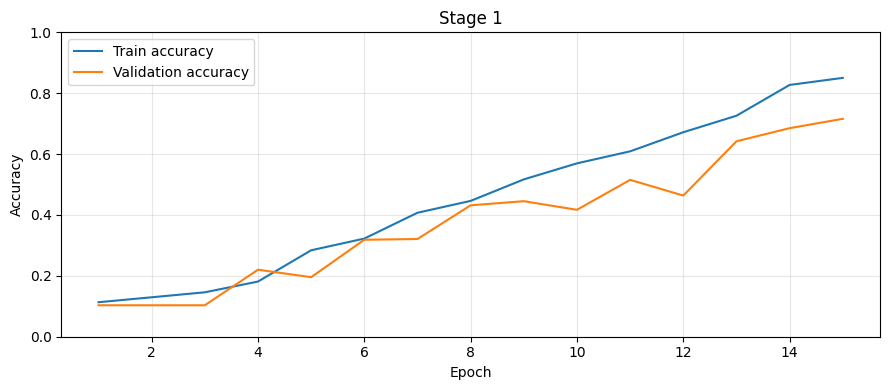

In [7]:
model_s1, history_s1 = run_stage(1, MANUAL_TRAIN_DIR)

<a id="stage2"></a>
# STAGE 2: RAW + CENTERED — 3.796 ẢNH TRAIN
Giữ nguyên mọi ảnh train thủ công và bổ sung một bản căn giữa, cùng nhãn. Train có p95 lệch tâm bbox≈6,78pixel ở ảnh32 nên có cơ sở thử căn giữa; giữ raw giúp mô hình tiếp tục thấy cách trình bày nguyên dạng. Padding15% tương ứng occupancy lý tưởng≈76,92%, chưa chứng minh tối ưu. Ngưỡng215 tương đương mọi cutoff(64,255] trên train nguồn hiện tại; bước tẩy nền đổi0pixel. Không biến đổi validation/Label Book.

Kết quả là hiệu quả của toàn bộ pipeline (cả thêm view/steps), không quy riêng cho căn giữa.

**Kết quả hiện tại:** checkpoint epoch 10, validation **681/813 = 83,76%**, Label Book **35/52 = 67,31%**. So với Stage 1, tăng **12,18 điểm phần trăm** trên validation và **3,85 điểm phần trăm** trên Label Book. Đây là bằng chứng cho cả pipeline raw + centered trong lần chạy này, chưa tách tác dụng của căn giữa khỏi tăng số ảnh/bước cập nhật.

In [8]:
def preprocess_and_center_numeral(img_pil, target_size=(32, 32), pad_ratio=0.15):
    gray = img_pil.convert("L")
    arr = np.array(gray)
    arr[arr > 215] = 255 # Tẩy trắng nền scan
    ys, xs = np.where(arr < 215)
    if len(ys) == 0:
        return None
    ymin, ymax = ys.min(), ys.max()
    xmin, xmax = xs.min(), xs.max()
    h = ymax - ymin + 1
    w = xmax - xmin + 1
    max_dim = max(h, w)
    pad = int(max_dim * pad_ratio)
    total_size = max_dim + 2 * pad
    canvas = np.ones((total_size, total_size), dtype=np.uint8) * 255
    crop = arr[ymin:ymax+1, xmin:xmax+1]
    canvas[(total_size-h)//2:(total_size-h)//2+h, (total_size-w)//2:(total_size-w)//2+w] = crop
    canvas[canvas < 120] = (canvas[canvas < 120] * 0.7).astype(np.uint8) # Boost tương phản
    res = Image.fromarray(canvas).resize(target_size, Image.Resampling.BILINEAR)
    return res.convert("RGB")

## 1. TẠO TRAIN HỖN HỢP: ẢNH GỐC + BẢN CĂN GIỮA

In [9]:
STAGE2_DIR = fresh_train_dir("stage2_mixed_train")
for c in CLASS_NAMES:
    for f in sorted((MANUAL_TRAIN_DIR / c).glob("*.png")):
        shutil.copyfile(f, STAGE2_DIR / c / ("raw_" + f.name))
        with Image.open(f) as im:
            proc = preprocess_and_center_numeral(im, target_size=IMAGE_SIZE)
        if proc is not None:
            proc.save(STAGE2_DIR / c / ("center_" + f.name))
print("Stage 2 train (giữ đầy đủ ảnh gốc):", len(list(STAGE2_DIR.glob("*/*.png"))))
assert_eval_unchanged()

Stage 2 train (giữ đầy đủ ảnh gốc): 3796


## 2. HUẤN LUYỆN VÀ ĐÁNH GIÁ TRÊN HAI TẬP GỐC

Found 3796 files belonging to 10 classes.
Epoch 1/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.1130 - loss: 2.3596
Epoch 1: val_accuracy improved from None to 0.12669, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage2_best_val_accuracy.weights.h5

Epoch 1: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage2_best_val_accuracy.weights.h5
119/119 ━━━━━━━━━━━━━━━━━━━━ 34s 210ms/step - accuracy: 0.1225 - loss: 2.3105 - val_accuracy: 0.1267 - val_loss: 2.2977
Epoch 2/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.1795 - loss: 2.2167
Epoch 2: val_accuracy improved from 0.12669 to 0.24477, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage2_best_val_accuracy.weights.h5

Epoch 2: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage2_best_val_accuracy.weights.h5
119/119 ━━━━━━━━━━━━━━━━━━━━ 17s

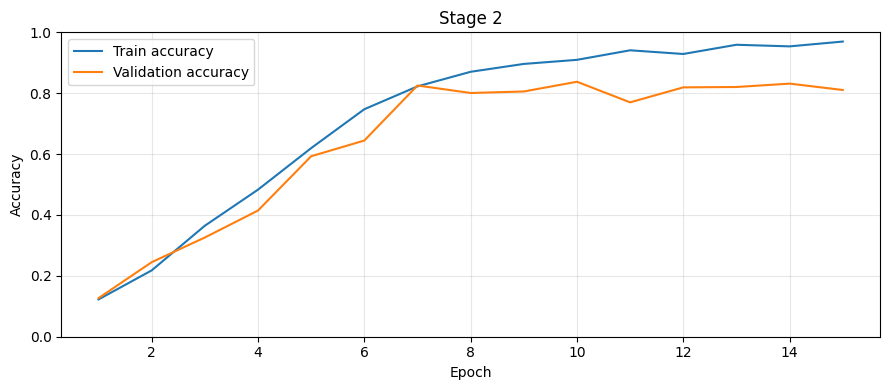

In [10]:
model_s2, history_s2 = run_stage(2, STAGE2_DIR)

<a id="stage3"></a>
# STAGE 3: CÂN BẰNG VÀ AUGMENTATION — 7.500 ẢNH TRAIN
Nguồn gồm raw và centered của Stage 2; 750 ảnh/lớp. Xoay ±6°, dịch/zoom 8%, fill trắng, không lật.

Checkpoint epoch 10 đạt validation **718/813 = 88,31%**, Label Book **43/52 = 82,69%**. So với Stage 2, tăng **4,55 điểm phần trăm** trên validation và **15,38 điểm phần trăm** trên Label Book. Đây là Label Book cao nhất trong sáu checkpoint được chọn theo validation của lần chạy hiện tại; không dùng kết quả đó để chọn lại mô hình.

750 là cấu hình đã chạy, chưa chứng minh tối ưu. Target đều tối thiểu giữ hai view của lớp lớn nhất hiện là 546/lớp; chưa chạy đối chứng theo số ảnh nên không khẳng định 750 tốt hơn mọi target khác. Kết quả phản ánh đồng thời cân bằng lớp, augmentation và số bước cập nhật.

## 1. TẠO TẬP CÂN BẰNG 7.500 ẢNH


In [11]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

def build_balanced_train(name, target, rotation):
    dest = fresh_train_dir(name)
    datagen = ImageDataGenerator(rotation_range=rotation, width_shift_range=0.08,
                                height_shift_range=0.08, zoom_range=0.08,
                                fill_mode="constant", cval=255.0, horizontal_flip=False)
    for c in CLASS_NAMES:
        files = sorted((STAGE2_DIR / c).glob("*.png"))
        if not 0 < len(files) <= target:
            raise ValueError(f"Lớp {c}: cần 1..{target} ảnh nguồn, có {len(files)}")
        pool = []
        for i, f in enumerate(files):
            with Image.open(f) as im:
                pool.append(np.array(im.convert("RGB").resize(IMAGE_SIZE, Image.Resampling.BILINEAR)))
            shutil.copyfile(f, dest / c / f"original_{i:04d}.png")
        it = datagen.flow(np.array(pool), batch_size=1, shuffle=True, seed=RANDOM_SEED)
        for i in range(target - len(pool)):
            Image.fromarray(next(it)[0].astype(np.uint8)).save(dest / c / f"aug_{i:04d}.png")
        assert len(list((dest / c).glob("*.png"))) == target
    assert_eval_unchanged()
    print("Train:", dest, target * len(CLASS_NAMES))
    return dest

STAGE3_DIR = build_balanced_train("stage3_balanced_train", 750, 6)

Train: /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage3_balanced_train 7500


## 2. HUẤN LUYỆN TRÊN 7.500 ẢNH TRAIN

Found 7500 files belonging to 10 classes.
Epoch 1/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.1070 - loss: 2.3338
Epoch 1: val_accuracy improved from None to 0.10332, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage3_best_val_accuracy.weights.h5

Epoch 1: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage3_best_val_accuracy.weights.h5
235/235 ━━━━━━━━━━━━━━━━━━━━ 35s 115ms/step - accuracy: 0.1117 - loss: 2.3084 - val_accuracy: 0.1033 - val_loss: 2.2866
Epoch 2/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.2160 - loss: 2.0720
Epoch 2: val_accuracy improved from 0.10332 to 0.25707, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage3_best_val_accuracy.weights.h5

Epoch 2: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage3_best_val_accuracy.weights.h5
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 

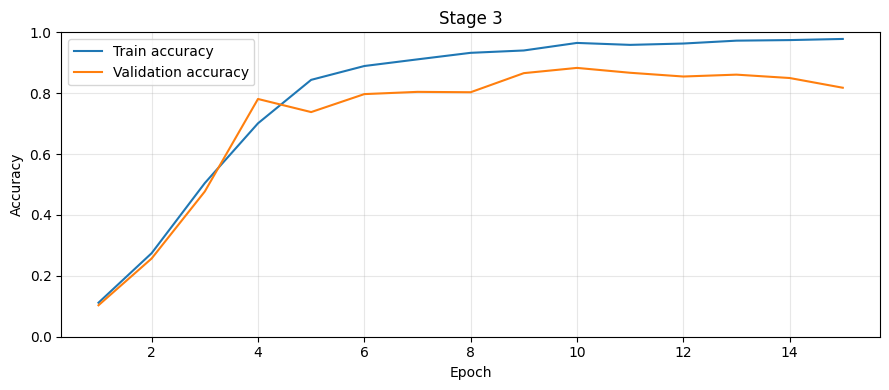

In [12]:
model_s3, history_s3 = run_stage(3, STAGE3_DIR)

<a id="stage4"></a>
# STAGE 4: NATIVE MIXED — 9.500 ẢNH TRAIN
Giữ train thủ công, sinh thêm view ở độ phân giải nguồn rồi resize, 950 ảnh/lớp. Cùng mô hình và 15 epoch; tập đánh giá nguyên trạng. Đây là cả gói thay đổi số ảnh/view/interpolation, chưa tách từng nguyên nhân.

**Checkpoint epoch 14 được chọn cho toàn notebook**: validation **729/813 = 89,67%**, cao nhất sáu stage; Label Book **41/52 = 78,85%**. So với Stage 3, validation tăng **1,35 điểm phần trăm** (11 ảnh đúng), nhưng Label Book giảm **3,85 điểm phần trăm** (2 ảnh đúng). Vì vậy native mixed cải thiện validation trong lần chạy này, chưa cho thấy cải thiện trên Label Book. Quy tắc chọn validation vẫn giữ Stage 4.

## 1. TẠO 9.500 ẢNH TRAIN

In [13]:
import random
from PIL import ImageOps, ImageEnhance, ImageFilter

def train_canvas(image, pad_ratio=0.22):
    gray = image.convert("L")
    arr = np.asarray(gray)
    ys, xs = np.where(arr < 215)
    if len(ys) == 0:
        return gray.convert("RGB")
    crop = gray.crop((int(xs.min()), int(ys.min()), int(xs.max())+1, int(ys.max())+1))
    side = max(crop.size)
    pad = max(4, round(side * pad_ratio))
    canvas = Image.new("L", (side + 2*pad, side + 2*pad), 255)
    canvas.paste(crop, ((canvas.width-crop.width)//2, (canvas.height-crop.height)//2))
    return canvas.convert("RGB")

def augment_native_train(image, rng, advanced=False):
    # Majority of views preserve original framing/background. Train images only.
    normalized_probability = 0.35 if advanced else 0.25
    im = (train_canvas(image, rng.uniform(0.12, 0.35))
          if rng.random() < normalized_probability else image.convert("RGB"))
    border = max(2, round(max(im.size)*0.10))
    im = ImageOps.expand(im, border=border, fill="white")
    w, h = im.size
    angle = np.deg2rad(rng.uniform(-6, 6))
    scale = rng.uniform(0.94, 1.06)
    shear = rng.uniform(-0.06, 0.06) if advanced else 0.0
    rotation = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
    linear = rotation @ np.array([[scale, shear], [0.0, scale]])
    center = np.array([(w-1)/2, (h-1)/2])
    shift = np.array([rng.uniform(-0.04,0.04)*w, rng.uniform(-0.04,0.04)*h])
    forward = np.eye(3)
    forward[:2,:2] = linear
    forward[:2,2] = center + shift - linear @ center
    inverse = np.linalg.inv(forward)
    out = im.transform((w,h), Image.Transform.AFFINE, tuple(inverse[:2].reshape(-1)),
                       resample=Image.Resampling.BILINEAR, fillcolor="white")
    mask = np.asarray(out.convert("L")) < 160
    if mask[0,:].any() or mask[-1,:].any() or mask[:,0].any() or mask[:,-1].any():
        out = im  # Do not keep transforms that cut through a stroke at the border.
    if advanced:
        out = ImageEnhance.Contrast(out).enhance(rng.uniform(0.85,1.15))
        if min(out.size) >= 96 and rng.random() < 0.10:
            out = out.filter(ImageFilter.MinFilter(3))  # Mild high-res thickening only.
        if rng.random() < 0.15:
            out = out.filter(ImageFilter.GaussianBlur(rng.uniform(0.15,0.4)))
    return out

def build_native_mixed_train(name, target, advanced=False):
    dest = fresh_train_dir(name)
    rng = random.Random(RANDOM_SEED)
    for c in CLASS_NAMES:
        files = sorted((MANUAL_TRAIN_DIR / c).glob("*.png"))
        if not 0 < len(files) <= target:
            raise ValueError(f"Lớp {c}: cần 1..{target} ảnh train sạch, có {len(files)}")
        pool = []
        for i, f in enumerate(files):
            shutil.copyfile(f, dest / c / f"original_{i:04d}.png")
            with Image.open(f) as im:
                pool.append(im.convert("RGB"))
        for i in range(target-len(pool)):
            # Cycle sources equally within a class; generate distinct native-res views.
            im = augment_native_train(pool[i % len(pool)], rng, advanced=advanced)
            im.resize(IMAGE_SIZE, Image.Resampling.LANCZOS).save(dest / c / f"aug_{i:04d}.png")
        assert len(list((dest / c).glob("*.png"))) == target
    assert_eval_unchanged()
    print("Train hỗn hợp:", target*len(CLASS_NAMES), "ảnh; giữ ảnh gốc và chỉ augment train.")
    return dest

AUGMENTED_DIR = build_native_mixed_train("stage4_native_mixed_train", 950)

Train hỗn hợp: 9500 ảnh; giữ ảnh gốc và chỉ augment train.


## 2. HUẤN LUYỆN VÀ ĐÁNH GIÁ

Found 9500 files belonging to 10 classes.
Epoch 1/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.1018 - loss: 2.3255
Epoch 1: val_accuracy improved from None to 0.22386, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage4_best_val_accuracy.weights.h5

Epoch 1: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage4_best_val_accuracy.weights.h5
297/297 ━━━━━━━━━━━━━━━━━━━━ 43s 115ms/step - accuracy: 0.1084 - loss: 2.3028 - val_accuracy: 0.2239 - val_loss: 2.1328
Epoch 2/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.2452 - loss: 1.9618
Epoch 2: val_accuracy improved from 0.22386 to 0.48954, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage4_best_val_accuracy.weights.h5

Epoch 2: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage4_best_val_accuracy.weights.h5
297/297 ━━━━━━━━━━━━━━━━━━━━ 13s

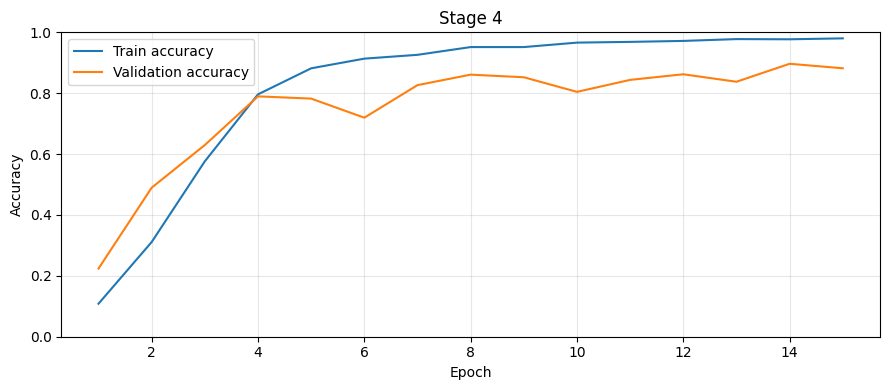

In [14]:
model_s4, history_s4 = run_stage(4, AUGMENTED_DIR)

<a id="stage5_superior"></a>
# STAGE 5: ADVANCED — 9.900 ẢNH TRAIN
Nguồn manual train nguyên vẹn; thêm view native cùng shear/contrast/blur/thickening nhẹ. Giữ 990 ảnh/lớp, cùng mô hình và 15 epoch. Không thay đổi tập đánh giá.

Checkpoint epoch 15 đạt validation **723/813 = 88,93%**, Label Book **42/52 = 80,77%**. So với Stage 4, validation giảm **0,74 điểm phần trăm** (6 ảnh đúng), Label Book tăng **1,92 điểm phần trăm** (1 ảnh đúng). Stage 5 không được chọn vì validation thấp hơn Stage 4. Tên advanced mô tả pipeline, không có nghĩa hiệu quả tốt hơn; chưa chứng minh từng phép biến đổi bổ sung có lợi và chưa đạt Label Book 90%.

In [15]:
# Stage 5 tái sử dụng augment_native_train(..., advanced=True) của Stage 4.
# Không tạo pipeline chuẩn hóa riêng cho validation hay Label Book.
assert_eval_unchanged()

In [16]:
SUPERIOR_DIR = build_native_mixed_train("stage5_native_mixed_train", 990, advanced=True)

Train hỗn hợp: 9900 ảnh; giữ ảnh gốc và chỉ augment train.


In [17]:
# Mọi stage dùng chung val_ds_raw và lb_ds_raw; không tạo tập đánh giá Superior riêng.
assert_eval_unchanged()

Found 9900 files belonging to 10 classes.
Epoch 1/15
310/310 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.1120 - loss: 2.3237
Epoch 1: val_accuracy improved from None to 0.27921, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage5_best_val_accuracy.weights.h5

Epoch 1: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage5_best_val_accuracy.weights.h5
310/310 ━━━━━━━━━━━━━━━━━━━━ 28s 58ms/step - accuracy: 0.1310 - loss: 2.2646 - val_accuracy: 0.2792 - val_loss: 1.8996
Epoch 2/15
310/310 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3186 - loss: 1.7277
Epoch 2: val_accuracy improved from 0.27921 to 0.56089, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage5_best_val_accuracy.weights.h5

Epoch 2: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage5_best_val_accuracy.weights.h5
310/310 ━━━━━━━━━━━━━━━━━━━━ 11s 3

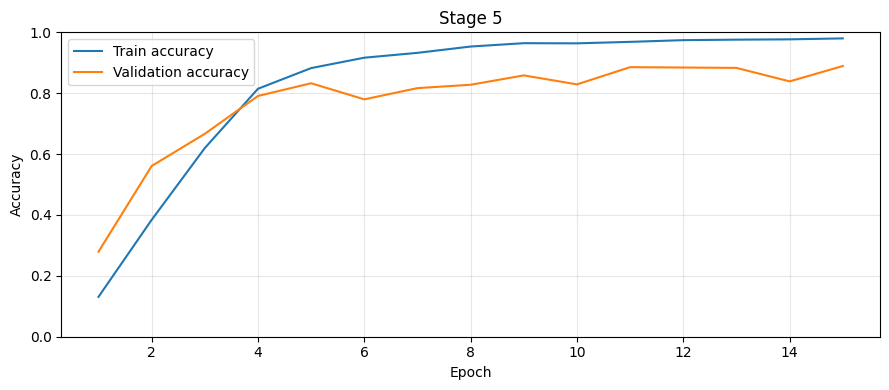

In [18]:
superior_model, history_s5 = run_stage(5, SUPERIOR_DIR)

<a id="stage6_eval"></a>
# PHẦN 6: TỔNG HỢP ACCURACY
Cả sáu stage đã chạy và đánh giá checkpoint có validation accuracy cao nhất, tách biệt với kết quả epoch cuối in trong log. Bảng so sánh dùng checkpoint được chọn, không trộn với epoch cuối. Label Book chỉ dùng báo cáo, không dùng chọn epoch hoặc stage.

## 1. CHỌN STAGE THEO VALIDATION ACCURACY
Chọn stage có accuracy validation cao nhất; không đọc Label Book khi lựa chọn.

In [19]:
assert_eval_unchanged()
missing=set(range(6))-BEST_CHECKPOINT_DETAILS.keys()
if missing:raise RuntimeError(f"Chưa có kết quả accuracy cho stage: {sorted(missing)}")
SELECTED_STAGE=max(sorted(BEST_CHECKPOINT_DETAILS),key=lambda i:BEST_CHECKPOINT_DETAILS[i]["validation"]["metrics"]["accuracy"])
SELECTED_DETAILS=BEST_CHECKPOINT_DETAILS[SELECTED_STAGE]
SELECTED_EPOCH=BEST_CHECKPOINT_EPOCHS[SELECTED_STAGE]
SELECTED_CHECKPOINT=FAIR_ROOT/f"stage{SELECTED_STAGE}_best_val_accuracy.weights.h5"
print(f"Chọn theo validation accuracy: Stage {SELECTED_STAGE}, epoch {SELECTED_EPOCH}")
display(pd.DataFrame({s:d["metrics"] for s,d in SELECTED_DETAILS.items()}).T)
def load_selected_model():
    if not SELECTED_CHECKPOINT.is_file():raise FileNotFoundError("Cần file weights từ runtime đã chạy; notebook không chứa weights.")
    model=build_fixed_vgg16_model();model.load_weights(str(SELECTED_CHECKPOINT));return model

Chọn theo validation accuracy: Stage 4, epoch 14


,accuracy,n_correct,n_samples
validation,0.896679,729.0,813.0
label_book,0.788462,41.0,52.0


## 2. ACCURACY CỦA MÔ HÌNH ĐƯỢC CHỌN
Stage 4, epoch 14: **validation 729/813 = 89,67%**, **Label Book 41/52 = 78,85%**. Số đúng/tổng kiểm tra trực tiếp công thức accuracy. Đây là checkpoint tốt nhất theo validation trong lần chạy hiện tại.

In [20]:
for split,title in [("validation","Validation gốc"),("label_book","Label Book gốc")]:
    m=SELECTED_DETAILS[split]["metrics"]
    print(f"{title}: {m['n_correct']}/{m['n_samples']} = {m['accuracy']:.2%}")

Validation gốc: 729/813 = 89.67%
Label Book gốc: 41/52 = 78.85%


## 3. SO SÁNH ACCURACY CÁC STAGE
Bảng và biểu đồ dưới dùng checkpoint đạt `val_accuracy` cao nhất của mỗi stage; nếu hòa giữ epoch đầu tiên. Cả sáu checkpoint đều đã có điểm Label Book trong lần chạy này; không còn trường hợp chưa đo của bản tổng hợp cũ.

Validation không tăng ở mọi bước: Stage 1 thấp hơn baseline, Stage 2–4 tăng, Stage 5 giảm nhẹ. Label Book cao nhất tại Stage 3, khác với Stage 4 được chọn theo validation. Hai tập có thứ hạng khác nhau nên không kết luận mọi stage sau đều tốt hơn stage trước.

Accuracy-only — cùng tiêu chí val_accuracy cho mọi stage


,checkpoint_epoch,validation_accuracy,validation_correct,validation_total,label_book_accuracy,label_book_correct,label_book_total
stage,,,,,,,
0,15,0.7466,607,813,0.5962,31,52
1,15,0.7159,582,813,0.6346,33,52
2,10,0.8376,681,813,0.6731,35,52
3,10,0.8831,718,813,0.8269,43,52
4,14,0.8967,729,813,0.7885,41,52
5,15,0.8893,723,813,0.8077,42,52


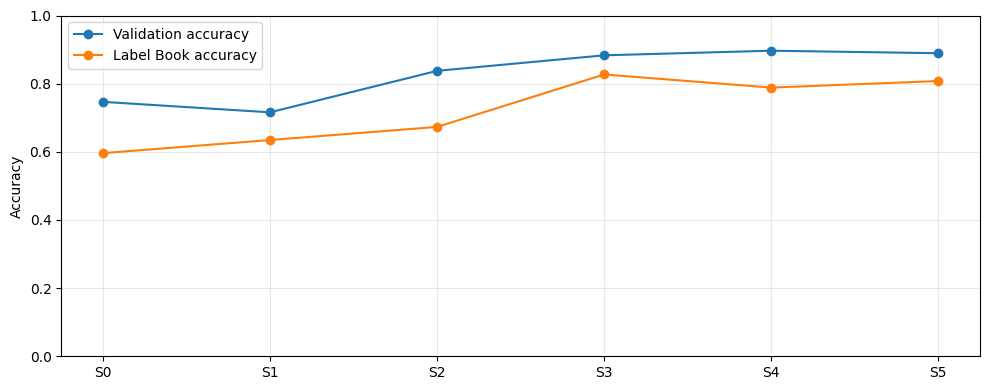

In [21]:
assert_eval_unchanged()
rows=[]
for i in range(6):
    v=BEST_CHECKPOINT_DETAILS[i]["validation"]["metrics"]
    b=BEST_CHECKPOINT_DETAILS[i]["label_book"]["metrics"]
    rows.append(dict(stage=i,checkpoint_epoch=BEST_CHECKPOINT_EPOCHS[i],
                     validation_accuracy=v["accuracy"],validation_correct=v["n_correct"],validation_total=v["n_samples"],
                     label_book_accuracy=b["accuracy"],label_book_correct=b["n_correct"],label_book_total=b["n_samples"]))
table=pd.DataFrame(rows).set_index("stage")
print("Accuracy-only — cùng tiêu chí val_accuracy cho mọi stage")
display(table.round(4));table.to_csv(FAIR_ROOT/"accuracy_comparison.csv")
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(table.index,table["validation_accuracy"],marker="o",label="Validation accuracy")
ax.plot(table.index,table["label_book_accuracy"],marker="o",label="Label Book accuracy")
ax.set_xticks(range(6),[f"S{i}" for i in range(6)]);ax.set_ylim(0,1);ax.set_ylabel("Accuracy")
ax.legend();ax.grid(alpha=0.3);fig.tight_layout();plt.show()

## 4. KẾT LUẬN

- **Chọn Stage 4, epoch 14 theo validation accuracy:** 729/813 = **89,67%**; Label Book 41/52 = **78,85%**. So với baseline, tăng 15,01 điểm phần trăm trên validation và 19,23 điểm phần trăm trên Label Book.
- **Stage 3, epoch 10 có Label Book cao nhất trong sáu checkpoint được báo cáo:** 43/52 = **82,69%**, validation 718/813 = **88,31%**. Đây là quan sát để thảo luận, không dùng thay đổi quy tắc lựa chọn. Mục tiêu Label Book 90% chưa đạt; cần ít nhất 47/52 ảnh đúng.
- Clean thủ công ở Stage 1 tăng Label Book từ 31 lên 33 ảnh đúng, nhưng validation giảm từ 607 xuống 582 ảnh đúng. Raw + centered và cân bằng/augmentation ở Stage 2–3 tăng accuracy trên cả hai tập so với stage liền trước trong lần chạy này. Stage 4/5 thể hiện đánh đổi giữa validation và Label Book, không chứng minh pipeline càng phức tạp càng tốt.
- Mỗi stage mới có một lần chạy, cùng 15 epoch nhưng khác số optimizer updates. Vì vậy chưa chứng minh ý nghĩa thống kê, chưa tách riêng tác dụng của từng thay đổi, và chưa chứng minh các target 750/950/990 hay biên augmentation là tối ưu. Label Book chỉ có 52 ảnh: một ảnh tương ứng khoảng 1,92 điểm phần trăm.
- Giữ nguyên validation và Label Book; nguồn train thủ công không bị clean lại. Audit có 49 ảnh train trùng validation, nên validation chưa độc lập hoàn toàn với train. Không có ảnh train trùng Label Book theo phép kiểm tra pixel/kích thước hiện có.
- Đây là bản đồ án VGG16. Cuộc thi gốc còn ràng buộc mô hình ResNet50 và ngân sách train + validation; Stage 4/5 vượt ngân sách gốc. Báo cáo accuracy không đồng nghĩa đáp ứng mọi điều kiện nộp thi gốc.